## 🕵️‍♂️ Практика 3: введение в поиск аномалий (Anomaly Detection)

Автор: [Пётр Рыбаков](https://github.com/pitfisher)

## 1. Теоретическая часть: Что такое аномалия?

Аномалия (выброс) — это наблюдение, которое настолько сильно отклоняется от остальных данных, что вызывает подозрение, что оно было сгенерировано совершенно другим процессом. \
В машинном обучении есть три основных типа аномалий: \
1. **Точечные (Point Anomalies)**: Отдельная точка сильно отличается от остальных (например, покупка на 1 млн рублей при обычном чеке в 1000 рублей).
2. **Контекстуальные (Contextual)**: Точка нормальна сама по себе, но аномальна в данном контексте (например, +30 градусов зимой — аномалия, а летом — норма).
3. **Коллективные (Collective)**: Группа точек по отдельности нормальна, но вместе они образуют странный паттерн (например, сердце бьется с идеальной частотой, но без малейших естественных вариаций — это признак сбоя кардиостимулятора).

**Главная проблема задачи:** У нас почти никогда нет размеченных данных (мы не знаем заранее, как выглядят все возможные аномалии). Поэтому поиск аномалий — это чаще всего задача **обучения без учителя (Unsupervised Learning)**. Мы показываем модели "нормальные" данные и просим запомнить, как выглядит "норма". Всё, что на неё не похоже — аномалия.

## 2. Подготовка среды и генерация данных

Чтобы понять, как работают алгоритмы, нам нужно их "увидеть". Мы создадим синтетический 2D-датасет: два облака "нормальных" точек и немного случайного "шума", который будет играть роль аномалий.

/tmp/ipykernel_1075/2621377905.py:29: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_anomalies[:, 0], X_anomalies[:, 1], c='red', marker='x', s=50, label='Аномалии (выбросы)', edgecolor='k')


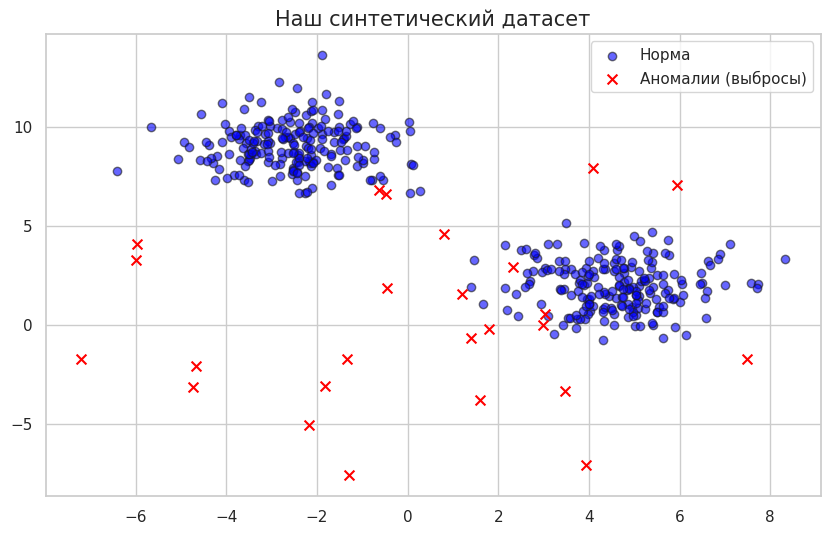

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.metrics import classification_report, f1_score, confusion_matrix

# Настройка стиля графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Генерируем "нормальные" данные (два кластера)
X_normal, _ = make_blobs(n_samples=400, centers=2, cluster_std=1.2, random_state=42)

# 2. Генерируем аномалии (равномерно разбросанные точки по всей области)
X_anomalies = np.random.uniform(low=-8, high=8, size=(25, 2))

# 3. Объединяем
X = np.vstack([X_normal, X_anomalies])

# Создаем метки для проверки (0 - норма, 1 - аномалия)
# В реальности таких меток у нас нет, но они нужны для оценки качества
y_true = np.zeros(425)
y_true[400:] = 1

# Визуализация
plt.scatter(X_normal[:, 0], X_normal[:, 1], c='blue', label='Норма', alpha=0.6, edgecolor='k')
plt.scatter(X_anomalies[:, 0], X_anomalies[:, 1], c='red', marker='x', s=50, label='Аномалии (выбросы)', edgecolor='k')
plt.title("Наш синтетический датасет", fontsize=15)
plt.legend()
plt.show()

## 3. Четыре кита поиска аномалий

В библиотеке `scikit-learn` есть три самых популярных алгоритма, которые основаны на совершенно разных математических идеях.


>⚠️ Важно: В `sklearn` алгоритмы поиска аномалий возвращают `1` для нормальных объектов и `-1` для аномалий. Мы будем приводить их к привычному виду (0 и 1).
Также нам понадобится параметр `contamination` (загрязнение) — это наша гипотеза о том, какую долю аномалий мы ожидаем в данных (от 0 до 0.5).

### Метод 1: Elliptic Envelope (Статистический подход)

**Идея:** Алгоритм предполагает, что нормальные данные имеют многомерное нормальное распределение (Гауссиану). Он пытается "обернуть" основную массу данных в эллипс. Всё, что вышло за границы эллипса — аномалия.

*   **Плюсы:** Быстрый, понятный.
*   **Минусы:** Работает только если данные действительно похожи на эллипс/гауссиану. Плохо справляется со сложными формами.

In [ ]:
from sklearn.covariance import EllipticEnvelope

# contamination=0.08 означает, что мы ожидаем около 8% аномалий
ee = EllipticEnvelope(contamination=0.08, random_state=42)
ee.fit(X)

# Предсказание (1 - норма, -1 - аномалия)
y_pred_ee = ee.predict(X)
# Переводим в формат 0 (норма) и 1 (аномалия)
y_pred_ee = (y_pred_ee == -1).astype(int)

print("Отчет по Elliptic Envelope:")
print(classification_report(y_true, y_pred_ee, target_names=["Норма", "Аномалия"]))

Отчет по Elliptic Envelope:
              precision    recall  f1-score   support

       Норма       0.98      0.96      0.97       400
    Аномалия       0.50      0.68      0.58        25

    accuracy                           0.94       425
   macro avg       0.74      0.82      0.77       425
weighted avg       0.95      0.94      0.95       425



### Метод 2: Isolation Forest (Изолирующий лес)

**Идея:** Гениальный алгоритм на основе деревьев решений. Представьте, что мы случайным образом выбираем признак и случайным образом "разрезаем" данные линией.
*   Нормальные точки лежат кучно, чтобы их изолировать, нужно сделать много разрезов.
*   Аномалии лежат далеко от всех, поэтому они "изолируются" (отделяются от остальных) за 1-2 случайных разреза!
*   **Плюсы:** Очень быстрый, отлично работает с данными высокой размерности, не требует предположений о форме данных.



In [ ]:
from sklearn.ensemble import IsolationForest

iforest = IsolationForest(contamination=0.08, random_state=42)
iforest.fit(X)

y_pred_if = iforest.predict(X)
y_pred_if = (y_pred_if == -1).astype(int)

print("Отчет по Isolation Forest:")
print(classification_report(y_true, y_pred_if, target_names=["Норма", "Аномалия"]))

Отчет по Isolation Forest:
              precision    recall  f1-score   support

       Норма       0.98      0.96      0.97       400
    Аномалия       0.50      0.68      0.58        25

    accuracy                           0.94       425
   macro avg       0.74      0.82      0.77       425
weighted avg       0.95      0.94      0.95       425



### Метод 3: One-Class SVM (Одноклассовый метод опорных векторов)

**Идея:** Алгоритм пытается найти границу (гиперплоскость), которая максимально плотно "обнимает" нормальные данные, отсекая всё остальное пространство. С помощью ядрового трюка (kernel trick) он может рисовать границы любой, самой причудливой формы.

*   **Плюсы:** Может находить аномалии в данных очень сложной, нелинейной формы.
* **Минусы:** Вычислительно сложный, медленно работает на больших датасетах (тысячи строк).

In [ ]:
from sklearn.svm import OneClassSVM

ocsvm = OneClassSVM(nu=0.08, kernel="rbf", gamma='auto')
ocsvm.fit(X)

y_pred_svm = ocsvm.predict(X)
y_pred_svm = (y_pred_svm == -1).astype(int)

print("Отчет по One-Class SVM:")
print(classification_report(y_true, y_pred_svm, target_names=["Норма", "Аномалия"]))

Отчет по One-Class SVM:
              precision    recall  f1-score   support

       Норма       0.96      0.89      0.92       400
    Аномалия       0.20      0.44      0.27        25

    accuracy                           0.86       425
   macro avg       0.58      0.66      0.60       425
weighted avg       0.92      0.86      0.88       425



## Метод 4: Local Outlier Factor (LOF, локальный уровень выброса)

**Идея:** объект считается аномалией, если его **локальная плотность** заметно ниже, чем у его ближайших соседей. В отличие от глобальных методов (Elliptic Envelope, Isolation Forest оценивают «удалённость от всех данных»), LOF сравнивает объект только с его непосредственным окружением. Благодаря этому он находит **локальные выбросы** в данных с regions разной плотности — там, где глобальные методы слепы.

**Как считается (концептуально):**
1.   Для каждого объекта находим `n_neighbors` ближайших соседей.
2.   Считаем reachability-расстояния — расстояния до соседей, но не меньше «радиуса окружения» самого соседа (чтобы не завышать плотность плотных кластеров).
3.   Local Reachability Density (LRD) — локальная плотность объекта: величина, обратная среднему reachability-расстоянию до его соседей.
4.   LOF — отношение средней плотности соседей к плотности самого объекта:
     *   **LOF ≈ 1** — плотность как у соседей → норма;
     *   **LOF >> 1** — объект в «разрежении» относительно соседей → аномалия;
     *   **LOF < 1** — объект внутри плотного кластера.

Важные нюансы в sklearn:
*   `novelty=False` (по умолчанию): модель применяется **только к данным, на которых обучалась**, через `fit_predict`. Это режим «поиск выбросов внутри выборки».
*   `novelty=True`: модель обучается на норме и затем оценивает **новые** объекты (`predict`, `decision_function`, `score_samples`). Это режим, нужный для продакшена.
*   Score хранится «перевёрнутым»: атрибут `negative_outlier_factor_` и метод `score_samples` возвращают −**LOF**: норма ≈ −1, аномалии уходят в −3, −7 и ниже.
*   Метод основан на расстояниях → **масштабирование признаков обязательно**.

In [ ]:
from sklearn.neighbors import LocalOutlierFactor

# novelty=False: поиск выбросов "внутри выборки"
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.08)
y_pred_lof_raw = lof.fit_predict(X)

# приводим к формату 0 (норма) / 1 (аномалия)
y_pred_lof = (y_pred_lof_raw == -1).astype(int)

print("Отчет по Local Outlier Factor:")
print(classification_report(y_true, y_pred_lof, target_names=["Норма", "Аномалия"]))

Отчет по Local Outlier Factor:
              precision    recall  f1-score   support

       Норма       0.98      0.96      0.97       400
    Аномалия       0.56      0.76      0.64        25

    accuracy                           0.95       425
   macro avg       0.77      0.86      0.81       425
weighted avg       0.96      0.95      0.95       425



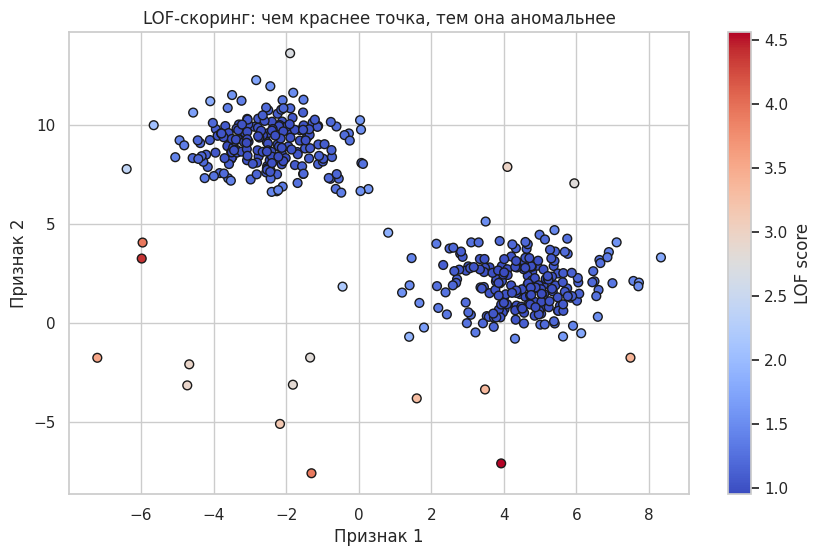

In [ ]:
# Визуализация LOF-скоринга: вернём привычную шкалу LOF (1 - норма, >1 - аномалия)
lof_scores = -lof.negative_outlier_factor_

plt.figure(figsize=(10, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=lof_scores, cmap='coolwarm', s=40, edgecolor='k')
plt.colorbar(scatter, label='LOF score')
plt.title("LOF-скоринг: чем краснее точка, тем она аномальнее")
plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.show()

Почему важна именно локальность:

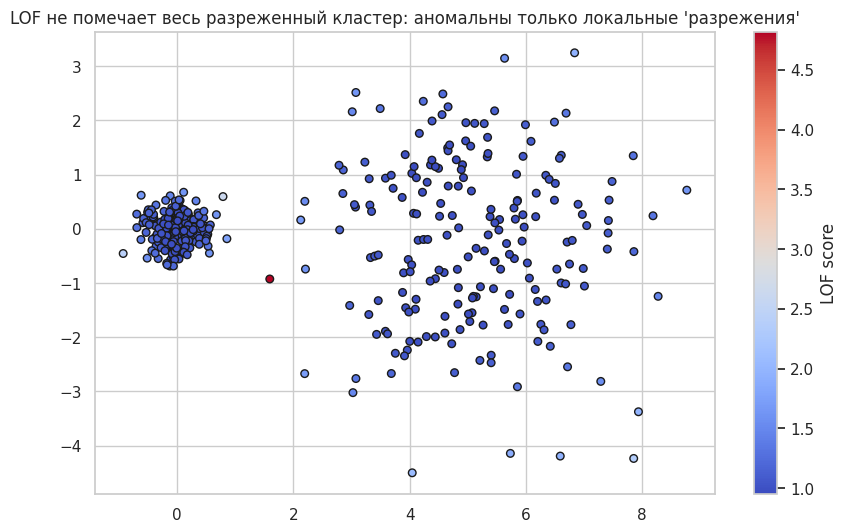

In [ ]:
# Мини-демо: два кластера РАЗНОЙ плотности
np.random.seed(7)

dense_cluster = np.random.normal(loc=[0, 0], scale=0.3, size=(200, 2))
sparse_cluster = np.random.normal(loc=[5, 0], scale=1.5, size=(200, 2))
X_mix = np.vstack([dense_cluster, sparse_cluster])

lof_mix = LocalOutlierFactor(n_neighbors=20)
lof_mix.fit_predict(X_mix)
scores_mix = -lof_mix.negative_outlier_factor_

plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_mix[:, 0], X_mix[:, 1], c=scores_mix, cmap='coolwarm', s=30, edgecolor='k')
plt.colorbar(scatter, label='LOF score')
plt.title("LOF не помечает весь разреженный кластер: аномальны только локальные 'разрежения'")
plt.show()

Разреженный кластер целиком **не** является аномалией для LOF — у каждой его точки соседи такой же низкой плотности. Глобальный плотностный метод пометил бы весь разреженный кластер как выброс, а LOF помечает только точки, которые разрежены **относительно своего окружения**.

LOF особенно полезен в мониторинге, где «норма» неоднородна: например, нагрузка на сервис днём и ночью имеет разную плотность, и подозрительным является не абсолютное значение метрики, а её отклонение от локального режима работы системы.

## 4. Визуализация "Границ решений" (Decision Boundaries)

Давайте посмотрим, как каждый алгоритм "видит" границу между нормой и аномалией. Это поможет развить интуицию.

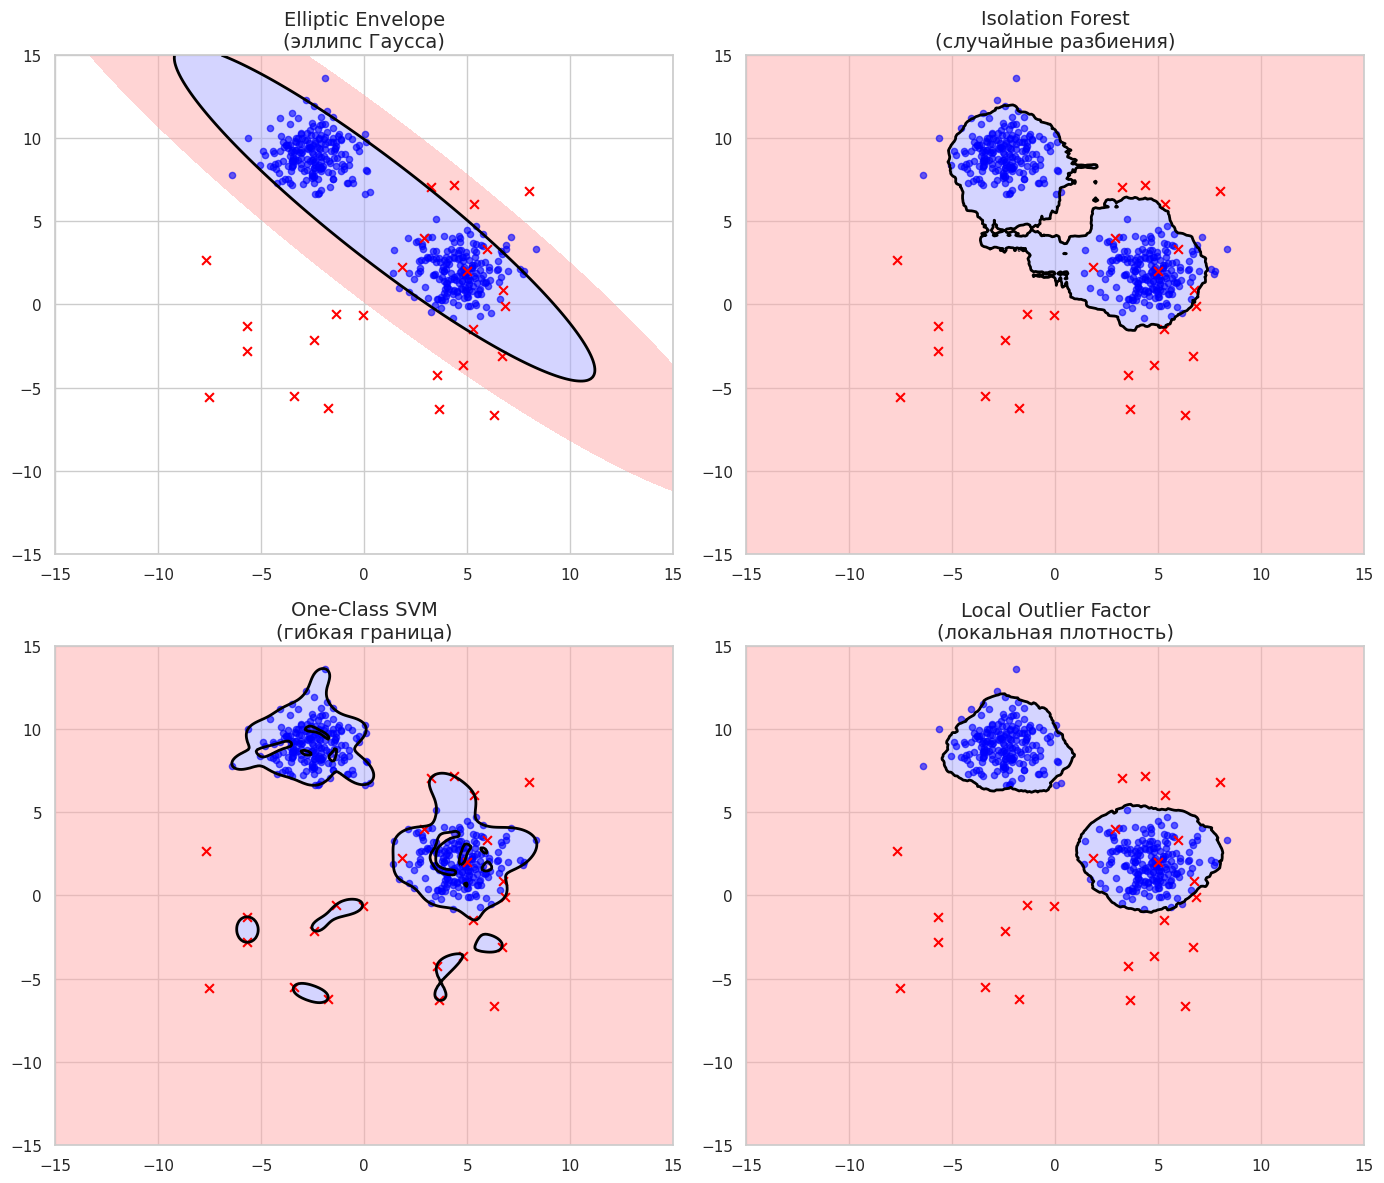

In [ ]:
# Создаем сетку для отрисовки фона
xx, yy = np.meshgrid(np.linspace(-15, 15, 300), np.linspace(-15, 15, 300))

# Функция для отрисовки
def plot_decision_boundary(clf, title, ax):
    # decision_function возвращает расстояние до границы.
    # Z < 0 означает аномалию, Z > 0 - норму.
    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Рисуем фон: красный - аномалия, синий - норма
    ax.contourf(xx, yy, Z, levels=[-15, 0, 15], colors=['#FFAAAA', '#AAAAFF'], alpha=0.5)
    ax.contour(xx, yy, Z, levels=[0], colors='black', linewidths=2) # Сама граница

    # Накладываем точки
    ax.scatter(X_normal[:, 0], X_normal[:, 1], c='blue', s=20, alpha=0.6)
    ax.scatter(X_anomalies[:, 0], X_anomalies[:, 1], c='red', marker='x', s=40)

    ax.set_title(title, fontsize=14)
    ax.set_xlim(-15, 15)
    ax.set_ylim(-15, 15)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Копия LOF в режиме "новые данные": только так доступен decision_function
lof_vis = LocalOutlierFactor(n_neighbors=20, novelty=True, contamination=0.08)
lof_vis.fit(X)

plot_decision_boundary(ee, "Elliptic Envelope\n(эллипс Гаусса)", axes[0, 0])
plot_decision_boundary(iforest, "Isolation Forest\n(случайные разбиения)", axes[0, 1])
plot_decision_boundary(ocsvm, "One-Class SVM\n(гибкая граница)", axes[1, 0])
plot_decision_boundary(lof_vis, "Local Outlier Factor\n(локальная плотность)", axes[1, 1])

plt.tight_layout()
plt.show()

Обратите внимание на графики:


*   Elliptic Envelope просто натянул один большой эллипс.
*   Isolation Forest "нарезал" пространство на прямоугольные зоны (это особенность деревьев решений).
*   One-Class SVM плотно "обнял" оба кластера, создав две отдельные зоны.
*   Граница LOF «обтекает» каждый кластер своим контуром и адаптируется к локальной плотности — в этом её отличие от единого эллипса (EE) и от глобальной границы SVM.




## 5. Оценка качества: Почему Accuracy — это зло? (в данной задаче)

В задачах поиска аномалий мы сталкиваемся с **сильным дисбалансом классов**. Аномалий обычно 1-5%.
Если мы создадим "глупую" модель, которая *всегда* говорит "Это норма", её **Accuracy (точность) будет 95-99%**! Но пользы от неё ноль, ведь мы не поймали ни одной аномалии.
Поэтому используют другие метрики:
*   **Precision (Точность)**: Какая доля объектов, которые мы назвали аномалиями, действительно ими является? (Важно, если ложная тревога стоит дорого, например, блокировка карты клиента).
*   **Recall (Полнота)**: Какую долю от всех реальных аномалий мы смогли найти? (Важно, если пропуск аномалии катастрофичен, например, пропуск брака на производстве или опухоли на снимке).
*   **F1-Score**: Гармоническое среднее между Precision и Recall.

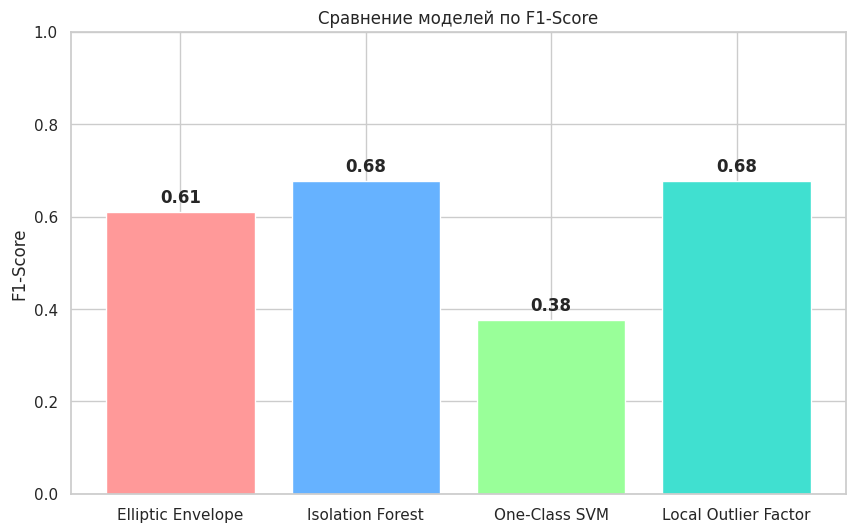

In [ ]:
# Сравним F1-score для всех трех моделей
models = {
    "Elliptic Envelope": y_pred_ee,
    "Isolation Forest": y_pred_if,
    "One-Class SVM": y_pred_svm,
    "Local Outlier Factor": y_pred_lof,
}

f1_scores = {name: f1_score(y_true, preds) for name, preds in models.items()}

plt.bar(f1_scores.keys(), f1_scores.values(), color=['#FF9999', '#66B2FF', '#99FF99', '#40E0D0'])
plt.ylabel("F1-Score")
plt.title("Сравнение моделей по F1-Score")
plt.ylim(0, 1)
for i, v in enumerate(f1_scores.values()):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', fontweight='bold')
plt.show()

## 6. Как это применять к реальным табличным данным?

В реальности у вас будет `pandas.DataFrame` с десятками колонок. Вот типичный пайплайн (алгоритм действий) для продакшена:

In [ ]:
%%time
# Допустим, у нас есть датасет с метриками серверов
data = {
    'cpu_load': [15, 18, 16, 17, 95, 14, 19, 16, 15, 18],
    'memory_mb': [2048, 2100, 2000, 2050, 15000, 2080, 2120, 2010, 2090, 2040],
    'network_errors': [0, 1, 0, 0, 450, 2, 0, 1, 0, 0]
}
df = pd.DataFrame(data)

# 1. Масштабирование признаков (ОБЯЗАТЕЛЬНО для SVM и Elliptic Envelope!)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 2. Обучение Isolation Forest (он лучше всего работает "из коробки")
clf = IsolationForest(contamination=0.1, random_state=42)
clf.fit(X_scaled)

df['anomaly_score'] = clf.decision_function(X_scaled) # Чем меньше, тем более аномально
df['is_anomaly'] = clf.predict(X_scaled)

# 3. Выводим топ самых подозрительных записей
print(df.sort_values('anomaly_score').head(5))

   cpu_load  memory_mb  network_errors  anomaly_score  is_anomaly
4        95      15000             450      -0.278795          -1
5        14       2080               2       0.030977           1
6        19       2120               0       0.063886           1
7        16       2010               1       0.091575           1
1        18       2100               1       0.097377           1
CPU times: user 316 ms, sys: 0 ns, total: 316 ms
Wall time: 324 ms


In [ ]:
%%time
feature_cols = ['cpu_load', 'memory_mb', 'network_errors']

# "Нормальная история": строки спокойного периода.
# В реальности её выделяет эксперт или окно времени без инцидентов.
normal_mask = df['cpu_load'] < 50

# Скейлер и LOF обучаем ТОЛЬКО на нормальных данных
scaler_lof = StandardScaler()
X_normal_hist = scaler_lof.fit_transform(df.loc[normal_mask, feature_cols])

# n_neighbors=4, т.к. объектов истории мало
# (правило: n_neighbors <= числа объектов обучения, обычно 10-50)
lof_prod = LocalOutlierFactor(n_neighbors=4, novelty=True)
lof_prod.fit(X_normal_hist)

# Оцениваем все текущие события
X_all = scaler_lof.transform(df[feature_cols])

df['lof_score'] = lof_prod.score_samples(X_all)   # чем отрицательнее, тем аномальнее
df['lof_is_anomaly'] = lof_prod.predict(X_all)    # 1 - норма, -1 - аномалия

print(df.sort_values('lof_score')[feature_cols + ['lof_score', 'lof_is_anomaly']])

   cpu_load  memory_mb  network_errors   lof_score  lof_is_anomaly
4        95      15000             450 -318.710801              -1
5        14       2080               2   -1.313096               1
6        19       2120               0   -1.125865               1
1        18       2100               1   -1.101226               1
8        15       2090               0   -1.054004               1
7        16       2010               1   -0.968887               1
0        15       2048               0   -0.955438               1
9        18       2040               0   -0.948476               1
3        17       2050               0   -0.942637               1
2        16       2000               0   -0.935583               1
CPU times: user 14.9 ms, sys: 10 µs, total: 14.9 ms
Wall time: 16.2 ms


In [ ]:
# Порог без разметки: по квантили скоринга нормальной истории.
# Помечаем top-5% самых аномальных по score событий.
threshold = np.quantile(lof_prod.score_samples(X_normal_hist), 0.05)
df['lof_flag_quantile'] = df['lof_score'] < threshold

print(df[['cpu_load', 'lof_score', 'lof_flag_quantile']])

   cpu_load   lof_score  lof_flag_quantile
0        15   -0.955438              False
1        18   -1.101226              False
2        16   -0.935583              False
3        17   -0.942637              False
4        95 -318.710801               True
5        14   -1.313096               True
6        19   -1.125865              False
7        16   -0.968887              False
8        15   -1.054004              False
9        18   -0.948476              False


*Комментарий*: строка с `cpu_load = 95` получит самый отрицательный `lof_score` — LOF в режиме `novelty=True` корректно оценил её как выброс относительно нормальной истории, хотя при обучении этой строки модель не видела.

## 7. Итоги и шпаргалка 📌

1.   **Isolation Forest** — ваш выбор по умолчанию. Работает быстро, не требует масштабирования данных, отлично справляется с большинством табличных данных.
2.   **One-Class SVM** — используйте, если данных немного, и вы уверены, что "норма" имеет сложную, специфическую форму, которую нужно аккуратно обвести. Требует обязательного масштабирования (StandardScaler).
3.   **Elliptic Envelope** — используйте только если вы уверены, что ваши данные распределены нормально (Гауссиана) и не имеют сложных "хвостов".
4.   **Local Outlier Factor** — выбирайте, когда данные имеют регионы **разной плотности** и важны **локальные** аномалии: объект может быть «нормальным глобально», но аномальным внутри своего окружения (и наоборот). Требует масштабирования. Ключевой переключатель: `novelty=False` — поиск внутри выборки (`fit_predict`), `novelty=True` — скоринг новых данных (`predict`, `score_samples`). Помните про «перевёрнутый» скор: чем отрицательнее `score_samples`, тем аномальнее объект.
5.   **Масштабирование**: Деревьям (Isolation Forest) всё равно на масштаб признаков, а вот методам, основанным на расстояниях и границах (SVM, Elliptic Envelope) — критически важно делать StandardScaler.
6.   **Оценка**: Никогда не смотрите на Accuracy. Всегда стройте classification_report и смотрите на Precision и Recall для класса аномалий, учитывая бизнес-логику (что дороже: ложная тревога или пропуск?).

Метод|Идея|Масштабирование|Новые данные|Когда выбирать
---|---|---|---|---
Elliptic Envelope|гауссов эллипс вокруг нормы|обязательно|да|данные близки к гауссовым
Isolation Forest|изоляция случайными разбиениями|не требуется|да|"по умолчанию| табличные данные"
One-Class SVM|гибкая граница вокруг нормы|обязательно|да|"мало данных| сложная форма нормы"
Local Outlier Factor|сравнение локальной плотности с соседями|обязательно|только при novelty=True|"разная плотность регионов| локальные выбросы"

*💡 **Совет для дальнейшей практики:** Попробуйте взять датасет из предыдущих семинаров (например, данные по автомобилям или кредитному скорингу), удалить целевую переменную, обучить `Isolation Forest` и посмотреть, какие объекты он сочтет аномальными. Часто аномалии в данных — это просто ошибки заполнения (опечатки, пропуски, введенные как 9999), и этот метод отлично помогает очищать данные (Data Cleaning)!*